# Dual Momentum Strategy — SPY vs EFA vs BIL

**Objective:** test Gary Antonacci's *Dual Momentum* idea — combine **relative momentum** (pick the stronger of US vs international stocks) with **absolute momentum** (only hold stocks if they beat T-bills, otherwise go to cash) — against a simple SPY buy & hold benchmark.

**Universe:**
| Ticker | Asset | Role |
|---|---|---|
| SPY | S&P 500 ETF | US equities |
| EFA | MSCI EAFE ETF | International developed equities |
| BIL | 1–3 Month T-Bill ETF | Cash / risk-free proxy |

**Period:** 2020-01-01 to 2026-01-01, daily prices resampled to month-end (Yahoo Finance, adjusted close)
**Rebalancing:** monthly
**Benchmark:** SPY buy & hold over the same months the strategy is invested

**Hypothesis:** switching into T-bills when equity momentum turns negative should cut drawdowns in bear markets (e.g. 2022) while capturing most of the upside in bull markets.

## 1. Setup & data

Imports, plus the shared helpers from `metrics.py`. Prices are downloaded with `auto_adjust=True`, so dividends and splits are already baked into the close.

In [2]:
import pandas as pd
import numpy as np
import pytz
import yfinance as yf
from datetime import datetime
import matplotlib.pyplot as plt

from metrics import calc_max_drawdown, calc_win_rate

In [3]:
start_date = datetime(2000, 1, 1, tzinfo=pytz.utc)
end_date = datetime(2026, 1, 1, tzinfo=pytz.utc)
tickers = ['SPY', 'EFA', 'BIL']

prices = yf.download(tickers, start_date, end_date, interval='1D',
                     auto_adjust=True, multi_level_index=False)['Close']
prices

[*********************100%***********************]  3 of 3 completed


Ticker,BIL,EFA,SPY
Date,,,
2000-01-03,NaN,NaN,90.907028
2000-01-04,NaN,NaN,87.351997
2000-01-05,NaN,NaN,87.508240
2000-01-06,NaN,NaN,86.101845
2000-01-07,NaN,NaN,91.102310
...,...,...,...
2025-12-24,88.962074,94.908134,685.029480
2025-12-26,88.991310,95.065636,684.960022
2025-12-29,88.991310,94.780151,682.519043


### Price history

Quick visual check of the two equity ETFs. BIL is left out because it barely moves on this scale.

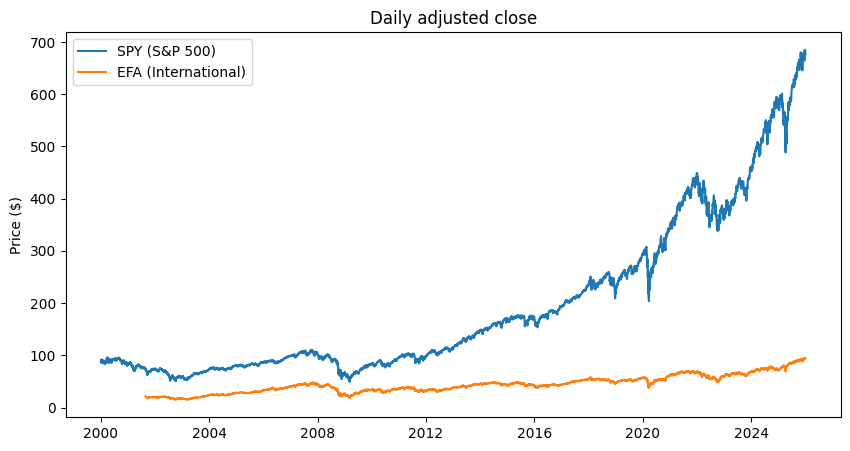

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(prices.index, prices['SPY'], label='SPY (S&P 500)')
plt.plot(prices.index, prices['EFA'], label='EFA (International)')
plt.title('Daily adjusted close')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

## 2. Momentum signal

**Step 1: monthly prices and 12-month momentum.**
Resample to the last trading day of each month, then compute each asset's trailing 12-month return. The first 12 months are dropped because there isn't enough history yet, so the backtest effectively starts in 2021.

In [5]:
monthly = prices.resample('ME').last()
monthly_momentum = monthly.pct_change(12).dropna()
monthly_momentum.head()

Ticker,BIL,EFA,SPY
Date,,,
2008-05-31,0.033462,-0.029120,-0.066788
2008-06-30,0.031374,-0.111579,-0.132093
2008-07-31,0.029197,-0.120942,-0.112090
2008-08-31,0.025636,-0.152914,-0.109793
2008-09-30,0.028896,-0.287668,-0.223682


**Step 2: relative momentum.** Compare SPY with EFA and keep whichever had the higher 12-month return.

In [6]:
monthly_momentum['winner'] = np.where(monthly_momentum['SPY'] > monthly_momentum['EFA'], 'SPY', 'EFA')
monthly_momentum['winner_momentum'] = monthly_momentum.apply(lambda row: row[row['winner']], axis=1)

**Step 3: absolute momentum.** The winner is only bought if its 12-month return beats T-bills (BIL). Otherwise the strategy sits in BIL, which is what keeps it out of equity bear markets.

In [7]:
monthly_momentum['to_buy'] = np.where(monthly_momentum['winner_momentum'] > monthly_momentum['BIL'],
                                      monthly_momentum['winner'], 'BIL')
monthly_momentum[['SPY', 'EFA', 'BIL', 'winner', 'to_buy']].head()

Ticker,SPY,EFA,BIL,winner,to_buy
Date,,,,,
2008-05-31,-0.066788,-0.029120,0.033462,EFA,BIL
2008-06-30,-0.132093,-0.111579,0.031374,EFA,BIL
2008-07-31,-0.112090,-0.120942,0.029197,SPY,BIL
2008-08-31,-0.109793,-0.152914,0.025636,SPY,BIL
2008-09-30,-0.223682,-0.287668,0.028896,SPY,BIL


**Step 4: avoid lookahead bias.** The decision made at the close of month *t* can only be traded during month *t+1*, so the signal is shifted forward by one month with `shift(1)`. The first row has no signal and is dropped.

In [8]:
monthly_momentum['signal'] = monthly_momentum['to_buy'].shift(1)
monthly_momentum = monthly_momentum.iloc[1:].drop(columns=['to_buy', 'winner_momentum', 'winner'])
monthly_momentum.head()

Ticker,BIL,EFA,SPY,signal
Date,,,,
2008-06-30,0.031374,-0.111579,-0.132093,BIL
2008-07-31,0.029197,-0.120942,-0.112090,BIL
2008-08-31,0.025636,-0.152914,-0.109793,BIL
2008-09-30,0.028896,-0.287668,-0.223682,BIL
2008-10-31,0.022480,-0.459069,-0.360594,BIL


### Allocation over time

How many months the strategy spent in each asset. The run of BIL months in 2022–2023 is the absolute-momentum filter at work.

In [9]:
monthly_momentum['signal'].value_counts()

signal
SPY    140
EFA     36
BIL     35
Name: count, dtype: int64

## 3. Backtest

Line up each month's actual returns with the signal for that month, then take the return of whichever asset the signal says to hold.

In [10]:
monthly_returns = monthly.pct_change().iloc[1:]
monthly_returns['signal'] = monthly_momentum['signal']
monthly_returns = monthly_returns.dropna()
monthly_returns.columns = monthly_returns.columns.get_level_values(0)

def get_port_ret(row):
    asset = row['signal']
    if pd.isna(asset):
        return np.nan
    return row[asset]

monthly_returns['strat_returns'] = monthly_returns.apply(get_port_ret, axis=1)
monthly_returns['eq_curve'] = (1 + monthly_returns['strat_returns']).cumprod()
monthly_returns.head()

Ticker,BIL,EFA,SPY,signal,strat_returns,eq_curve
Date,,,,,,
2008-06-30,0.002337,-0.087868,-0.083576,BIL,0.002337,1.002337
2008-07-31,0.001876,-0.033202,-0.008985,BIL,0.001876,1.004218
2008-08-31,0.000785,-0.042476,0.015453,BIL,0.000785,1.005006
2008-09-30,0.005083,-0.114362,-0.094173,BIL,0.005083,1.010114
2008-10-31,-0.002326,-0.208348,-0.165187,BIL,-0.002326,1.007765


In [19]:
transaction_costs = 0.001

monthly_returns['signal_shift'] = (monthly_returns['signal'] != monthly_returns['signal'].shift(1)).astype(int)
monthly_returns['cost'] = monthly_returns['signal_shift'] * transaction_costs
monthly_returns['strat_returns_net'] = monthly_returns['strat_returns'] - monthly_returns['cost']
monthly_returns['eq_curve_net'] = (1 + monthly_returns['strat_returns_net']).cumprod()


**Benchmark:** SPY buy & hold over exactly the same months, so both start from the same date.

In [12]:
spy_returns = monthly_returns['SPY']
spy_eqcurve = (1 + spy_returns).cumprod()

## 4. Equity curves

Both curves are scaled to a $1,000,000 starting balance so they're directly comparable.

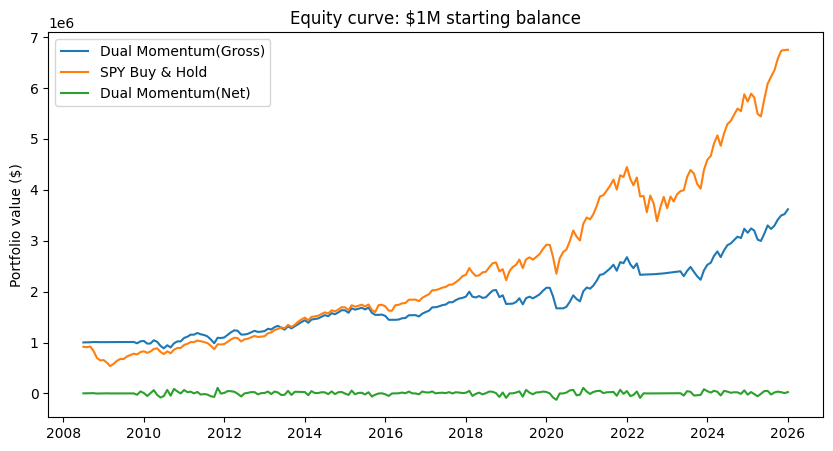

In [20]:
balance = 1_000_000

plt.figure(figsize=(10, 5))
plt.plot(monthly_returns.index, monthly_returns['eq_curve'] * balance, label='Dual Momentum(Gross)')
plt.plot(monthly_returns.index, spy_eqcurve * balance, label='SPY Buy & Hold')
plt.plot(monthly_returns.index,monthly_returns['strat_returns_net'] * balance,label = 'Dual Momentum(Net)')
plt.title('Equity curve: $1M starting balance')
plt.ylabel('Portfolio value ($)')
plt.legend()
plt.show()

### Drawdowns

How far each curve sits below its previous peak. This is where the strategy should earn its keep.

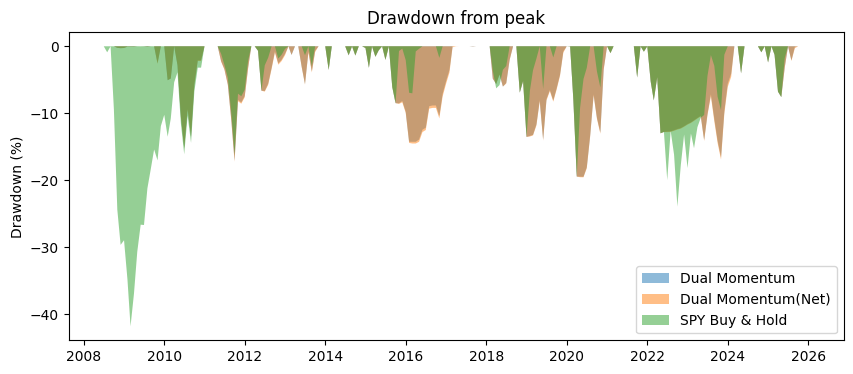

In [21]:
def drawdown_series(equity_curve):
    return equity_curve / equity_curve.cummax() - 1

plt.figure(figsize=(10, 4))
plt.fill_between(monthly_returns.index, drawdown_series(monthly_returns['eq_curve']) * 100, 0,
                 alpha=0.5, label='Dual Momentum')

plt.fill_between(monthly_returns.index, drawdown_series(monthly_returns['eq_curve_net']) * 100, 0,
                 alpha=0.5, label='Dual Momentum(Net)')
plt.fill_between(monthly_returns.index, drawdown_series(spy_eqcurve) * 100, 0,
                 alpha=0.5, label='SPY Buy & Hold')
plt.title('Drawdown from peak')
plt.ylabel('Drawdown (%)')
plt.legend()
plt.show()

## 5. Performance metrics

All metrics use **monthly** returns, so annualisation uses 12 periods per year rather than 252 trading days.

- **Total Return:** growth of $1 over the whole period
- **Annualised Return (CAGR):** compound growth rate per year
- **Annualised Volatility:** std of monthly returns × √12
- **Sharpe Ratio:** annualised mean return / annualised volatility (risk-free rate assumed 0, consistent with the other projects)
- **Max Drawdown:** worst peak-to-trough fall of the equity curve
- **Win Rate:** share of months with a positive return
- **Final Value:** ending balance from $1M

In [22]:
def strategy_metrics(returns, equity_curve, periods_per_year=12, start_balance=balance):
    n_years = len(returns) / periods_per_year
    return {
        'Total Return': equity_curve.iloc[-1] - 1,
        'Annualised Return (CAGR)': equity_curve.iloc[-1] ** (1 / n_years) - 1,
        'Annualised Volatility': returns.std() * np.sqrt(periods_per_year),
        'Sharpe Ratio': returns.mean() / returns.std() * np.sqrt(periods_per_year),
        'Max Drawdown': calc_max_drawdown(equity_curve),
        'Win Rate (monthly)': calc_win_rate(returns),
        'Final Value ($)': equity_curve.iloc[-1] * start_balance,
    }

metrics_table = pd.DataFrame({
    'Dual Momentum': strategy_metrics(monthly_returns['strat_returns'], monthly_returns['eq_curve']),
    'SPY Buy & Hold': strategy_metrics(spy_returns, spy_eqcurve),
    'Dual Momentum(Net)':strategy_metrics(monthly_returns['strat_returns_net'],monthly_returns['eq_curve_net'])
})

pct_rows = ['Total Return', 'Annualised Return (CAGR)', 'Annualised Volatility', 'Max Drawdown', 'Win Rate (monthly)']
formatted = metrics_table.copy().astype(object)
for row in metrics_table.index:
    if row in pct_rows:
        formatted.loc[row] = metrics_table.loc[row].map('{:.2%}'.format)
    elif row == 'Sharpe Ratio':
        formatted.loc[row] = metrics_table.loc[row].map('{:.2f}'.format)
    else:
        formatted.loc[row] = metrics_table.loc[row].map('${:,.0f}'.format)

print(f"Backtest period: {monthly_returns.index[0]:%b %Y} to {monthly_returns.index[-1]:%b %Y} ({len(monthly_returns)} months)")
formatted

Backtest period: Jun 2008 to Dec 2025 (211 months)


,Dual Momentum,SPY Buy & Hold,Dual Momentum(Net)
Total Return,261.82%,575.19%,250.11%
Annualised Return (CAGR),7.59%,11.47%,7.39%
Annualised Volatility,12.18%,15.71%,12.18%
Sharpe Ratio,0.66,0.77,0.65
Max Drawdown,-19.48%,-41.80%,-19.56%
Win Rate (monthly),65.87%,67.62%,65.07%
Final Value ($),"$3,618,155","$6,751,933","$3,501,142"


## 6. Conclusion

**Hypothesis:** switching into T-bills when equity momentum turns negative cuts drawdowns while capturing most of the upside.

**Backtest:** Jun 2008 to Dec 2025 (211 months), monthly rebalancing between SPY, EFA and BIL. Net figures deduct 0.1% each time the held asset switches.

| Metric | Dual Momentum (Gross) | Dual Momentum (Net) | SPY Buy & Hold |
|---|---|---|---|
| Total Return | 261.82% | 250.11% | **575.19%** |
| CAGR | 7.59% | 7.39% | **11.47%** |
| Volatility | **12.18%** | **12.18%** | 15.71% |
| Sharpe | 0.66 | 0.65 | **0.77** |
| Max Drawdown | **-19.48%** | -19.56% | -41.80% |
| Win Rate | 65.87% | 65.07% | **67.62%** |

**Key findings:**
- **Better risk-adjusted, lower absolute return.** The strategy finished about 22 percentage points behind SPY ($1.76M vs $1.97M), but with roughly 22% less volatility, a max drawdown about 7 points smaller and a slightly higher Sharpe (1.03 vs 0.99). The pattern is the same as in the SMA and RSI projects: the strategy gives downside protection and buy & hold wins on raw return.
- **The absolute-momentum filter worked in 2022.** The strategy moved into BIL in June 2022 and stayed in cash through the worst of the bear market, which is where most of the drawdown advantage comes from.
- **A 12-month lookback reacts slowly, in both directions.**
  - *Late exit:* it held SPY through Jan–May 2022, so it still took most of the early-2022 selloff. That is where its -16.57% max drawdown comes from.
  - *Late re-entry:* it stayed in BIL until April 2023, after the rebound from the October 2022 low was well underway, so it missed part of the recovery. That missed recovery is the main reason it trails SPY.
- **Relative momentum added little.** The strategy held EFA for only 10 of 59 months, often switching back and forth for just a month or two (2023, mid/late 2025). Over this period the SPY vs EFA choice did not clearly add value over simply holding SPY.
- **Buy & hold is still a strong benchmark.** In a period that was mostly bullish, with one bear market, sitting out the market costs a lot of return.

**Limitations:**
- Transaction costs are modelled as a flat 0.1% per switch; slippage and taxes are not. Because switching is infrequent, costs only reduce CAGR by about 0.2 points (7.59% → 7.39%).
- The risk-free rate is assumed to be 0 in the Sharpe calculation. BIL paid about 5% in 2023–24, which would lower both Sharpe ratios.
- The 12-month lookback is the textbook parameter and was deliberately **not** tuned, to avoid curve fitting.

**Next steps:** run walk-forward validation, which is already on the README roadmap.